# 08 · Topic-level sentiment — how do guests feel about each topic?
Combines notebook 06 (topics) with sentiment, at two levels:

1. **Review sentiment for every review** — *out-of-fold* predictions (5-fold, grouped by guest), so no review is scored by
   a model that saw it or its guest. (To use BERT instead, supply probabilities for **all** reviews in `PRED_FILE`.)
2. **Sentence sentiment** — a weakly-supervised classifier: each sentence inherits its review's label (reviews flagged in
   notebook 03 are excluded from training). This allows one review to be positive about location and negative about food.

**Outputs:** `outputs/dashboard/{reviews_enriched,sentences_enriched}.csv`, `outputs/topic_sentiment_summary.csv`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import mlflow, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, OUT = ROOT / "data" / "processed", ROOT / "outputs"
TOP, DASH = OUT / "topics", OUT / "dashboard"; DASH.mkdir(parents=True, exist_ok=True)
SEED = 42
LABELS = ["negative", "neutral", "positive"]; L2I = {l: i for i, l in enumerate(LABELS)}
COLORS = {"negative": "#D1495B", "neutral": "#B8BCC4", "positive": "#2E8B57"}
GENERAL = "General / Overall"
MLFLOW_URI = f"sqlite:///{ROOT / 'mlflow.db'}"
TOPIC_FILE = "sentence_topics.csv"        # or "sentence_topics_bertopic.csv" (notebook 07)
PRED_FILE = None                          # CSV with review_id, p_neg, p_neu, p_pos for ALL reviews (e.g. from BERT)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

rev = pd.read_csv(PROC / "reviews_full.csv")
rev["loyalty_status"] = rev["loyalty_status"].fillna("None")
issues = pd.read_csv(OUT / "label_issues.csv")
rev["label_issue"] = rev.review_id.isin(issues.review_id)

## 1. Review-level sentiment for every review (out-of-fold)

In [2]:
if PRED_FILE:
    p = pd.read_csv(PRED_FILE)
    rev = rev.merge(p[["review_id", "p_neg", "p_neu", "p_pos"]], on="review_id", how="left")
    probs = rev[["p_neg", "p_neu", "p_pos"]].values
else:
    probs = np.zeros((len(rev), 3)); y = rev.sentiment_label.map(L2I).values
    for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(rev, y, groups=rev.guest_id):
        A, Bd = rev.iloc[a], rev.iloc[b]
        v = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english"); o = OneHotEncoder(handle_unknown="ignore")
        Xa = hstack([v.fit_transform(A.review_text), o.fit_transform(A[["rating_bin"]].astype(str))]).tocsr()
        Xb = hstack([v.transform(Bd.review_text), o.transform(Bd[["rating_bin"]].astype(str))]).tocsr()
        probs[b] = LogisticRegression(C=1, max_iter=3000).fit(Xa, y[a]).predict_proba(Xb)
    rev[["p_neg", "p_neu", "p_pos"]] = probs
rev["pred_label"] = np.array(LABELS)[probs.argmax(1)]
rev_acc = float((rev.pred_label == rev.sentiment_label).mean())
print(f"review-level accuracy vs given labels: {rev_acc:.4f}")

review-level accuracy vs given labels: 0.9417


## 2. Sentence-level sentiment (weak supervision, out-of-fold)

In [3]:
sent = pd.read_csv(TOP / "sentences.csv")
m = sent.merge(rev[["review_id", "guest_id", "sentiment_label", "label_issue"]], on="review_id")
ym = m.sentiment_label.map(L2I).values
sp = np.zeros((len(m), 3))
for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(m, ym, groups=m.guest_id):
    A = m.iloc[a]; A = A[~A.label_issue]
    v = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    clf = LogisticRegression(C=1, max_iter=3000).fit(v.fit_transform(A.masked), A.sentiment_label.map(L2I))
    sp[b] = clf.predict_proba(v.transform(m.iloc[b].masked))
m[["sp_neg", "sp_neu", "sp_pos"]] = sp
m["sent_pred"] = np.array(LABELS)[sp.argmax(1)]
sent_acc = float((sp.argmax(1) == ym).mean())
print(f"sentence-level agreement with its review's label: {sent_acc:.4f}   (an upper bound is not 1.0: generic sentences are ambiguous)")

topics = pd.read_csv(TOP / TOPIC_FILE)[["review_id", "sent_idx", "category"]]
se = m.merge(topics, on=["review_id", "sent_idx"], how="left"); se["category"] = se.category.fillna(GENERAL)
se[["review_id", "sent_idx", "sentence", "category", "sent_pred", "sp_neg", "sp_neu", "sp_pos"]].to_csv(DASH / "sentences_enriched.csv", index=False)
named = se[se.category != GENERAL]
rev["topics"] = rev.review_id.map(named.groupby("review_id").category.agg(lambda s: "; ".join(sorted(set(s))))).fillna("")
keep = ["review_id", "booking_id", "guest_id", "hotel_id", "hotel_name", "location", "country", "star_rating", "room_type",
        "booking_channel", "customer_type", "loyalty_status", "total_amount", "stay_duration", "previous_stays", "review_date",
        "rating_score", "review_text", "sentiment_label", "pred_label", "p_neg", "p_neu", "p_pos", "label_issue", "topics"]
rev[keep].to_csv(DASH / "reviews_enriched.csv", index=False)
print(f"{len(se):,} sentences · {len(named):,} topic mentions · saved dashboard tables")

sentence-level agreement with its review's label: 0.8865   (an upper bound is not 1.0: generic sentences are ambiguous)


101,077 sentences · 77,265 topic mentions · saved dashboard tables


## 3. Sentiment by topic

In [4]:
g = named.groupby(["category", "sent_pred"]).size().unstack(fill_value=0).reindex(columns=LABELS, fill_value=0)
g["n"] = g[LABELS].sum(axis=1)
for l in LABELS: g[f"pct_{l}"] = (100 * g[l] / g.n).round(1)
g["net_sentiment"] = (g.pct_positive - g.pct_negative).round(1)
g = g.sort_values("net_sentiment"); g.to_csv(OUT / "topic_sentiment_summary.csv")
g[["n", "pct_negative", "pct_neutral", "pct_positive", "net_sentiment"]]

sent_pred,n,pct_negative,pct_neutral,pct_positive,net_sentiment
category,,,,,
Pricing,15292,14.4,69.4,16.2,1.8
Facilities,9665,24.4,48.7,26.9,2.5
Cleanliness,6725,29.1,38.2,32.7,3.6
Service,12145,24.4,47.2,28.5,4.1
Room quality,7017,21.8,52.0,26.3,4.5
Food,6931,21.3,49.4,29.3,8.0
Location,9813,23.1,41.6,35.4,12.3
Staff,9324,21.1,44.3,34.6,13.5
Comfort,353,0.0,0.0,100.0,100.0


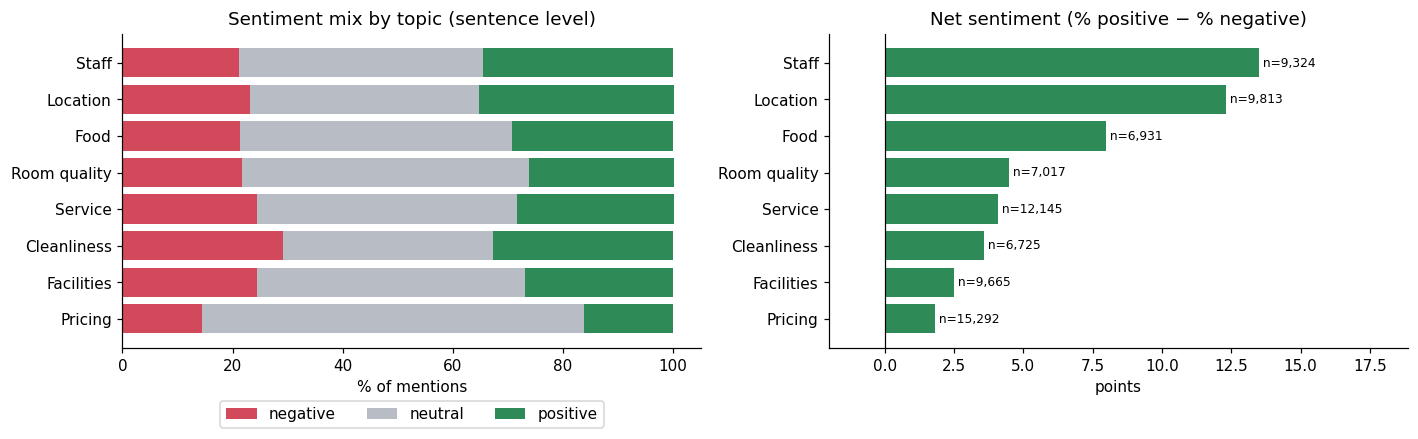

⚠ 'Comfort' omitted from the charts: only 353 mentions (100% positive / 0% neutral / 0% negative) — too few to compare reliably.


In [5]:
MIN_PLOT = 500                      # topics with fewer mentions would distort the scale (and are unreliable)
gp = g[g.n >= MIN_PLOT]
low = g[g.n < MIN_PLOT]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
left = np.zeros(len(gp))
for l in LABELS:
    ax[0].barh(gp.index, gp[f"pct_{l}"], left=left, color=COLORS[l], label=l); left += gp[f"pct_{l}"].values
ax[0].set(title="Sentiment mix by topic (sentence level)", xlabel="% of mentions"); ax[0].legend(ncol=3, loc="lower center", bbox_to_anchor=(.5, -.28))
ax[1].barh(gp.index, gp.net_sentiment, color=np.where(gp.net_sentiment >= 0, COLORS["positive"], COLORS["negative"]))
ax[1].axvline(0, color="k", lw=.8); ax[1].set(title="Net sentiment (% positive − % negative)", xlabel="points")
ax[1].set_xlim(min(0, gp.net_sentiment.min()) - 2, gp.net_sentiment.max() * 1.25 + 2)
for i, (n, v) in enumerate(zip(gp.n, gp.net_sentiment)): ax[1].text(v, i, f" n={n:,}", va="center", fontsize=8)
plt.tight_layout(); plt.show()
for c, r in low.iterrows():
    print(f"⚠ '{c}' omitted from the charts: only {int(r.n)} mentions ({r.pct_positive:.0f}% positive / {r.pct_neutral:.0f}% neutral / {r.pct_negative:.0f}% negative) — too few to compare reliably.")

## 4. Which topics *drive* positive vs negative reviews?
Sentence-level mix tells how guests feel *when they mention* a topic. A **driver** analysis asks the reverse: is a topic mentioned
*more often* in negative reviews than in positive ones? **Lift** = P(topic | negative review) ÷ P(topic overall). Lift well above 1
means complaints concentrate on that topic.

In [6]:
cats = sorted(named.category.unique())
for c in cats: rev[c] = rev.topics.str.contains(c, regex=False)
rate = pd.DataFrame({l: rev[rev.sentiment_label == l][cats].mean() * 100 for l in LABELS})
overall = rev[cats].mean() * 100
drv = rate.rename(columns=lambda l: f"% of {l} reviews").assign(**{"mention rate %": overall,
        "negative lift": rate.negative / overall, "positive lift": rate.positive / overall})
drv["avg rating when mentioned"] = [rev.loc[rev[c], "rating_score"].mean() for c in drv.index]
drv.round(2).sort_values("negative lift", ascending=False)

,% of negative reviews,% of neutral reviews,% of positive reviews,mention rate %,negative lift,positive lift,avg rating when mentioned
Cleanliness,21.89,15.82,20.57,19.14,1.14,1.07,3.00
Facilities,28.23,27.64,26.26,27.34,1.03,0.96,3.00
Service,34.00,33.45,33.01,33.46,1.02,0.99,3.02
Room quality,19.51,21.64,19.32,20.25,0.96,0.95,3.02
Location,26.48,24.58,31.89,27.59,0.96,1.16,3.11
Food,18.47,20.73,20.51,20.01,0.92,1.02,3.06
Staff,23.96,24.99,30.57,26.59,0.90,1.15,3.12
Pricing,32.70,52.63,30.34,39.45,0.83,0.77,2.99
Comfort,0.00,0.08,2.94,1.02,0.00,2.87,4.05


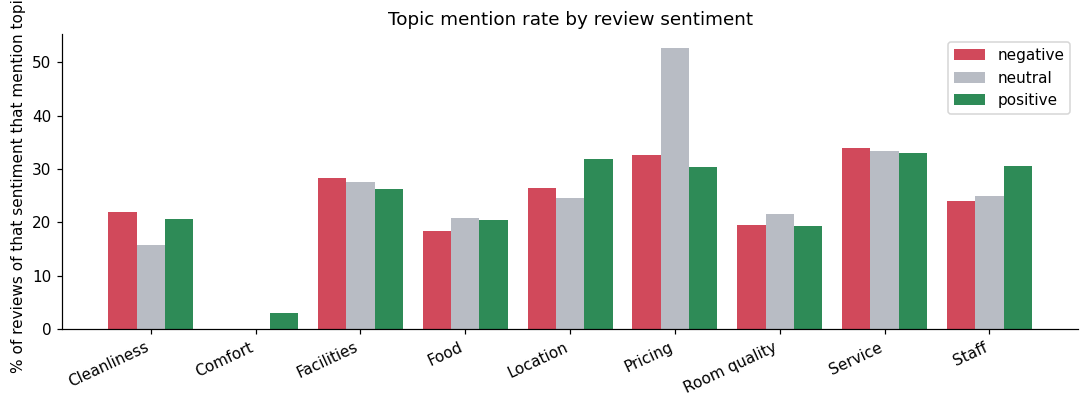

largest |lift − 1| across topics with ≥2% mention rate: 0.23
rare topics (excluded from that check): ['Comfort']
reviews with BOTH a positive and a negative topic: 0.00%

DATA NOTE: every topic is mentioned at similar rates in positive and negative reviews, so the topic mix barely explains sentiment in this dataset. Treat topic 'drivers' with caution; lift > 1.3 or < 0.7 would indicate a real driver.


In [7]:
fig, ax = plt.subplots(figsize=(10, 3.8)); x = np.arange(len(cats)); w = .27
for i, l in enumerate(LABELS): ax.bar(x + (i - 1) * w, rate[l], w, color=COLORS[l], label=l)
ax.set_xticks(x, cats, rotation=25, ha="right"); ax.set(ylabel="% of reviews of that sentiment that mention topic", title="Topic mention rate by review sentiment")
ax.legend(); plt.tight_layout(); plt.show()

big = drv.loc[[c for c in cats if rev[c].mean() >= 0.02]]       # ignore rare topics (<2% of reviews, e.g. Comfort)
spread = max((big["negative lift"] - 1).abs().max(), (big["positive lift"] - 1).abs().max())
mixed = float(named.groupby("review_id").sent_pred.agg(lambda s: {"positive", "negative"} <= set(s)).mean())
print(f"largest |lift − 1| across topics with ≥2% mention rate: {spread:.2f}")
print("rare topics (excluded from that check):", [c for c in cats if rev[c].mean() < 0.02])
print(f"reviews with BOTH a positive and a negative topic: {100 * mixed:.2f}%")
if spread < 0.3:
    print("\nDATA NOTE: every topic is mentioned at similar rates in positive and negative reviews, so the topic mix barely explains sentiment "
          "in this dataset. Treat topic 'drivers' with caution; lift > 1.3 or < 0.7 would indicate a real driver.")

## 5. Recurring complaints and praise (most common sentences per topic)

In [8]:
import re
loc_rx = re.compile(r"\b(" + "|".join(map(re.escape, rev.location.dropna().unique())) + r")\b", re.I)
lead = re.compile(r"^(?:(?:On the other hand|On top of that|In addition|Also|Plus|That said|Overall|Honestly|Sadly|Unfortunately),?\s+)+", re.I)
def top_sentences(cat, label, n=5):
    s = named[(named.category == cat) & (named.sent_pred == label)].sentence
    s = s.str.replace(loc_rx, "<city>", regex=True).str.replace(lead, "", regex=True).str.strip()
    return s.str[:1].str.upper().add(s.str[1:]).value_counts().head(n)
pd.concat({f"{c} · negative": top_sentences(c, "negative", 3) for c in ["Cleanliness", "Service", "Food", "Facilities"]}).to_frame("count")

count
                       sentence                                                 
Cleanliness · negative The housekeeping staff left a lot to be desired...     20
                       The bathroom left a lot to be desired; it clear...     17
                       Our suite left a lot to be desired; we found du...     16
Service · negative     Arrival left a lot to be desired; the system ap...     29
                       The check-in desk left a lot to be desired; we ...     28
                       The check-in process left a lot to be desired; ...     27
Food · negative        The buffet left a lot to be desired; several it...     29
                       The buffet left a lot to be desired; the same f...     28
                       The restaurant left a lot to be desired; severa...     22
Facilities · negative  The gym left a lot to be desired; it needed a s...     28
                       The gym left a lot to be desired; parts of it w...     26
                       The lounge left a lot to be desired; parts of i...     23

In [9]:
mlflow.set_tracking_uri(MLFLOW_URI); mlflow.set_experiment("guest-topic-sentiment")
with mlflow.start_run(run_name="topic_sentiment"):
    mlflow.log_metrics({"review_oof_accuracy": rev_acc, "sentence_oof_acc_vs_review_label": sent_acc,
                        "share_reviews_pos_and_neg_topics": mixed, "max_abs_lift_dev": float(spread)})

## Take-aways
* Topic-level sentiment is the *business-facing* output: it says which parts of the experience guests praise or criticise.
* The checks above are deliberately blunt about weak signal: if topics are mentioned equally in good and bad reviews, don't present
  them as drivers. That is exactly what the data note flags here.
* Next: explore everything interactively in notebook 09.